# 02 – Indicator Analysis

## Urban Heat Island Analysis – Voi Town, Kenya

This notebook analyses Land Surface Temperature (LST), Normalized Difference Vegetation Index (NDVI), and Normalized Difference Built-up Index (NDBI) from Landsat 8 and 9 imagery for 2016–2026.

In [1]:
import ee
import geemap
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

ee.Initialize(project='voi-urban-heat-island-analysis')

print("Libraries imported and Earth Engine initialized successfully.")

Libraries imported and Earth Engine initialized successfully.


In [2]:
# Define Voi study area
voi_point = ee.Geometry.Point([38.56, -3.39])
voi_aoi = voi_point.buffer(5000)

# Load Landsat 8
landsat_8 = (
    ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
    .filterBounds(voi_aoi)
    .filterDate('2016-01-01', '2026-10-01')
)

# Load Landsat 9
landsat_9 = (
    ee.ImageCollection('LANDSAT/LC09/C02/T1_L2')
    .filterBounds(voi_aoi)
    .filterDate('2022-01-01', '2026-10-01')
)

# Merge collections and retain L2SP scenes
landsat = (
    landsat_8.merge(landsat_9)
    .filter(ee.Filter.eq('PROCESSING_LEVEL', 'L2SP'))
)

print("Total Landsat scenes:", landsat.size().getInfo())

Total Landsat scenes: 331


In [3]:
def preprocess_landsat(image):

    qa = image.select('QA_PIXEL')

    mask = (
        qa.bitwiseAnd(1 << 0).eq(0)
        .And(qa.bitwiseAnd(1 << 1).eq(0))
        .And(qa.bitwiseAnd(1 << 2).eq(0))
        .And(qa.bitwiseAnd(1 << 3).eq(0))
        .And(qa.bitwiseAnd(1 << 4).eq(0))
        .And(qa.bitwiseAnd(1 << 5).eq(0))
    )

    mask = mask.And(image.select('QA_RADSAT').eq(0))

    optical = (
        image.select([
            'SR_B2', 'SR_B3', 'SR_B4',
            'SR_B5', 'SR_B6', 'SR_B7'
        ])
        .multiply(0.0000275)
        .add(-0.2)
    )

    ndvi = optical.normalizedDifference(
        ['SR_B5', 'SR_B4']
    ).rename('NDVI')

    ndbi = optical.normalizedDifference(
        ['SR_B6', 'SR_B5']
    ).rename('NDBI')

    lst = (
        image.select('ST_B10')
        .multiply(0.00341802)
        .add(149.0)
        .subtract(273.15)
        .rename('LST_C')
    )

    return (
        image.addBands(optical, overwrite=True)
        .addBands([ndvi, ndbi, lst])
        .updateMask(mask)
        .copyProperties(image, ['system:time_start'])
    )


landsat_processed = landsat.map(preprocess_landsat)

print("Processed scenes:", landsat_processed.size().getInfo())

Processed scenes: 331


In [4]:
years = list(range(2016, 2027))

annual_composites = {}

for year in years:

    composite = (
        landsat_processed
        .filterDate(f'{year}-06-01', f'{year}-10-01')
        .median()
        .clip(voi_aoi)
    )

    annual_composites[year] = composite

print("Composites generated:", len(annual_composites))

Composites generated: 11


In [5]:
# Store annual statistics
annual_stats = []

for year in years:

    image = annual_composites[year]

    stats = image.select([
        'LST_C', 'NDVI', 'NDBI'
    ]).reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=voi_aoi,
        scale=30,
        maxPixels=1e9
    ).getInfo()

    annual_stats.append({
        'Year': year,
        'Mean_LST_C': stats.get('LST_C'),
        'Mean_NDVI': stats.get('NDVI'),
        'Mean_NDBI': stats.get('NDBI')
    })

# Convert to DataFrame
df_stats = pd.DataFrame(annual_stats)

display(df_stats.round(4))

,Year,Mean_LST_C,Mean_NDVI,Mean_NDBI
0,2016,41.4410,0.3025,0.1085
1,2017,45.5631,0.2639,0.1510
2,2018,44.7180,0.3098,0.0997
3,2019,44.5315,0.3142,0.1131
4,2020,39.8644,0.3962,0.0400
5,2021,42.4282,0.2975,0.1192
6,2022,45.2181,0.2709,0.1389
7,2023,48.5725,0.2350,0.1661
8,2024,40.1094,0.3504,0.0704
9,2025,40.9238,0.3542,0.0685


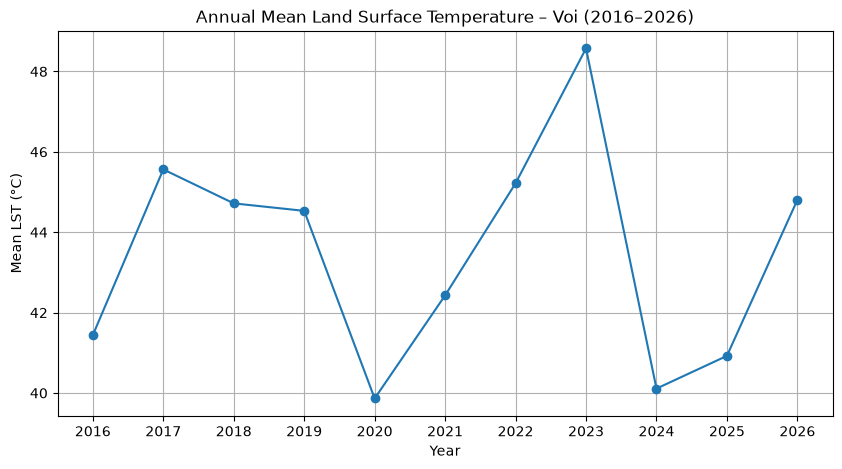

In [6]:
# Plot annual LST
plt.figure(figsize=(10, 5))
plt.plot(df_stats['Year'], df_stats['Mean_LST_C'], marker='o')
plt.title('Annual Mean Land Surface Temperature – Voi (2016–2026)')
plt.xlabel('Year')
plt.ylabel('Mean LST (°C)')
plt.grid(True)
plt.xticks(years)
plt.show()

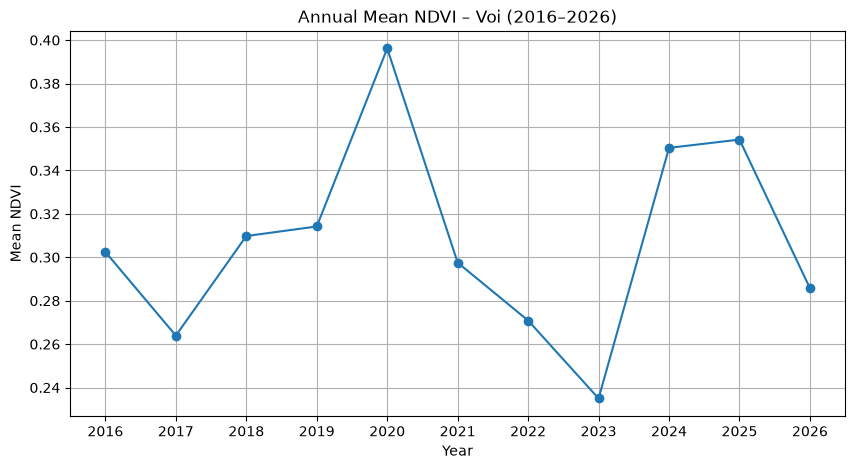

In [7]:
plt.figure(figsize=(10, 5))

plt.plot(
    df_stats['Year'],
    df_stats['Mean_NDVI'],
    marker='o'
)

plt.title('Annual Mean NDVI – Voi (2016–2026)')
plt.xlabel('Year')
plt.ylabel('Mean NDVI')
plt.grid(True)
plt.xticks(years)
plt.show()

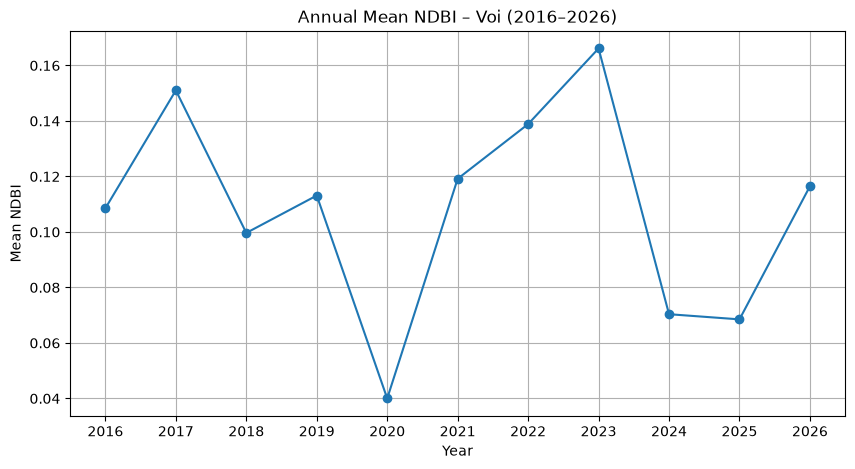

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(
    df_stats['Year'],
    df_stats['Mean_NDBI'],
    marker='o'
)

plt.title('Annual Mean NDBI – Voi (2016–2026)')
plt.xlabel('Year')
plt.ylabel('Mean NDBI')
plt.grid(True)
plt.xticks(years)
plt.show()

In [9]:
# Calculate correlation matrix
correlation_matrix = df_stats[
    ['Mean_LST_C', 'Mean_NDVI', 'Mean_NDBI']
].corr(method='pearson')

print("Correlation Matrix:")
display(correlation_matrix.round(3))

Correlation Matrix:


,Mean_LST_C,Mean_NDVI,Mean_NDBI
Mean_LST_C,1.000,-0.887,0.889
Mean_NDVI,-0.887,1.000,-0.988
Mean_NDBI,0.889,-0.988,1.000


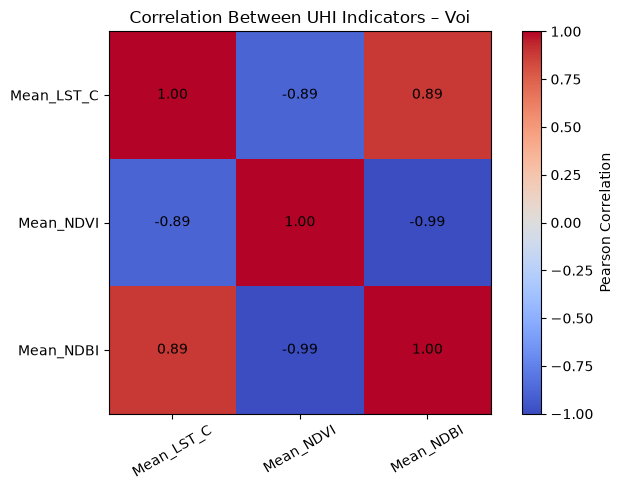

In [10]:
plt.figure(figsize=(7, 5))

plt.imshow(
    correlation_matrix,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.colorbar(label='Pearson Correlation')

plt.xticks(range(3), correlation_matrix.columns, rotation=30)
plt.yticks(range(3), correlation_matrix.columns)

for i in range(3):
    for j in range(3):
        plt.text(
            j, i,
            f'{correlation_matrix.iloc[i, j]:.2f}',
            ha='center',
            va='center'
        )

plt.title('Correlation Between UHI Indicators – Voi')
plt.tight_layout()
plt.show()

In [12]:
# Save annual indicator statistics
df_stats.to_csv(
    '../outputs/statistics/voi_annual_indicator_statistics.csv',
    index=False
)

# Save correlation matrix
correlation_matrix.to_csv(
    '../outputs/statistics/voi_indicator_correlation.csv'
)

print("Statistics and correlation matrix exported successfully!")

Statistics and correlation matrix exported successfully!
